In [1]:
# Setup and imports

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

Load the data

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

In [3]:
print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


Explore the data

In [4]:
print(x_train.dtype)
print(x_train.min(), x_train.max())

uint8
0 255


In [5]:
print(x_train[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0
    0   1   4   0   0   0   0   1   1   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62
   54   0   0   0   1   3   4   0   0   3]
 [  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134
  144 123  23   0   0   0   0  12  10   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178
  107 156 161 109  64  23  77 130  72  15]
 [  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216
  216 163 127 121 122 146 141  88 172  66]
 [  0   0   0   0   0   0   0   0   0   1   1   1   0 200 232 23

In [6]:
print(y_train[0])

9


In [7]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print(class_names[y_train[0]])

Ankle boot


In [8]:
unique, counts = np.unique(y_train, return_counts=True)
print(dict(zip(unique, counts)))

{np.uint8(0): np.int64(6000), np.uint8(1): np.int64(6000), np.uint8(2): np.int64(6000), np.uint8(3): np.int64(6000), np.uint8(4): np.int64(6000), np.uint8(5): np.int64(6000), np.uint8(6): np.int64(6000), np.uint8(7): np.int64(6000), np.uint8(8): np.int64(6000), np.uint8(9): np.int64(6000)}


Visualize

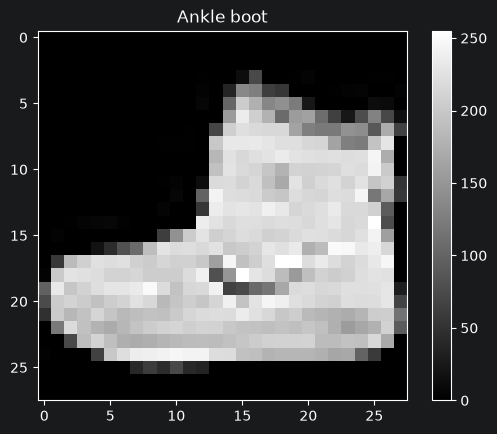

In [9]:
plt.figure()
plt.imshow(x_train[0], cmap='gray')
plt.colorbar()
plt.title(class_names[y_train[0]])
plt.show()

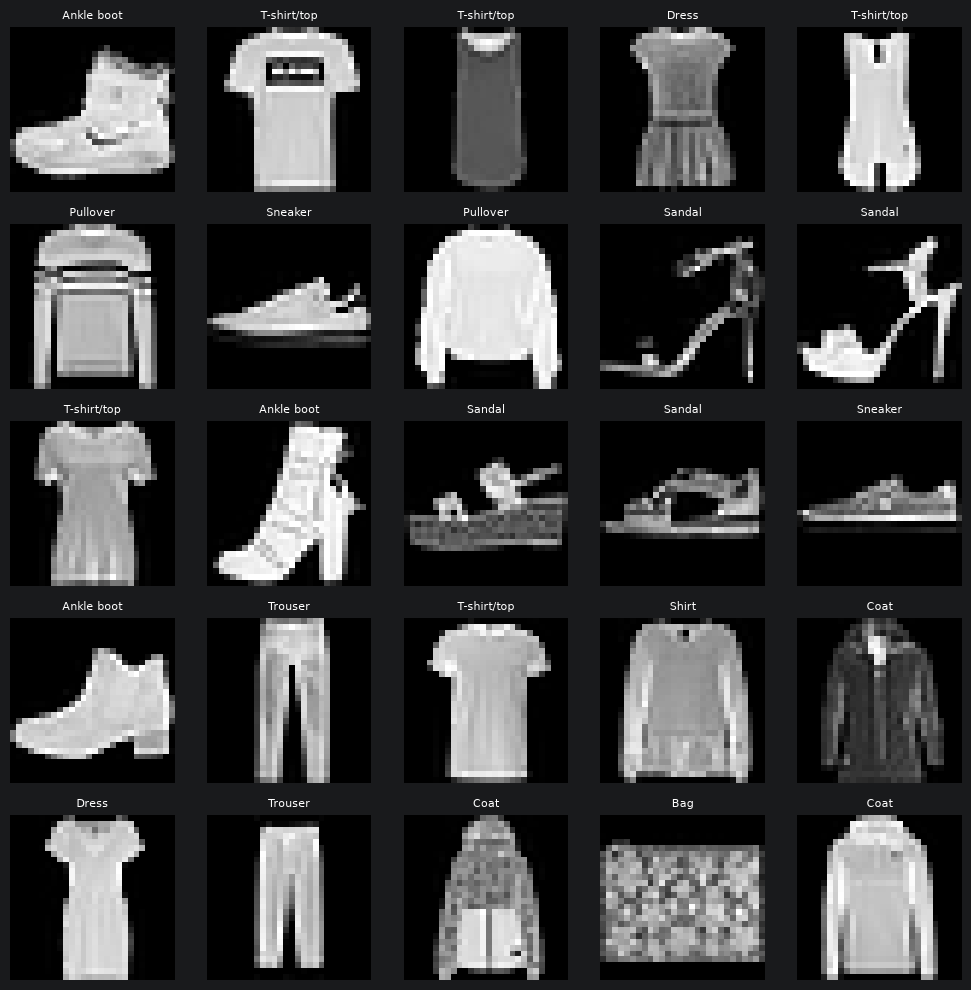

In [10]:
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]], fontsize=8)
    plt.axis('off')
plt.tight_layout()
plt.show()

Normalize the pixel values

In [11]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [12]:
print(x_train.dtype)
print(x_train.min(), x_train.max())
print(x_train.shape)

float32
0.0 1.0
(60000, 28, 28)


In [13]:
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

In [14]:
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [15]:
Split off a validation set

SyntaxError: invalid syntax (2215518259.py, line 1)

Split off a validation set

In [ ]:
x_val = x_train[:5000]
y_val = y_train[:5000]

x_train = x_train[5000:]
y_train = y_train[5000:]

Design the six-layer CNN

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax'),
])

model.summary()

Wrap the model in a Python class

In [ ]:
class FashionCNN:
    def __init__(self, input_shape=(28, 28, 1), num_classes=10):
        self.input_shape = input_shape
        self.num_classes = num_classes
        self.model = self._build()

    def _build(self):
        return keras.Sequential([
            layers.Input(shape=self.input_shape),
            layers.Conv2D(32, (3, 3), activation='relu'),
            layers.MaxPooling2D((2, 2)),
            layers.Conv2D(64, (3, 3), activation='relu'),
            layers.MaxPooling2D((2, 2)),
            layers.Flatten(),
            layers.Dense(128, activation='relu'),
            layers.Dense(self.num_classes, activation='softmax'),
        ], name="fashion_cnn")

    def summary(self):
        self.model.summary()

    def compile(self, learning_rate=0.001):
        self.model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )

    def train(self, x_train, y_train, x_val, y_val, epochs=10, batch_size=64):
        self.history = self.model.fit(
        x_train, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_data=(x_val, y_val),
    )
        return self.history

    def plot_history(self, save_path='training_curves.png'):
        h = self.history.history
        epoch_nums = range(1, len(h['accuracy']) + 1)

        plt.figure(figsize=(12, 4))

        plt.subplot(1, 2, 1)
        plt.plot(epoch_nums, h['accuracy'], label='Training')
        plt.plot(epoch_nums, h['val_accuracy'], label='Validation')
        plt.title('Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()

        plt.subplot(1, 2, 2)
        plt.plot(epoch_nums, h['loss'], label='Training')
        plt.plot(epoch_nums, h['val_loss'], label='Validation')
        plt.title('Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()

        plt.tight_layout()
        plt.savefig(save_path, dpi=150)
        plt.show()

    def evaluate(self, x_test, y_test):
        test_loss, test_acc = self.model.evaluate(x_test, y_test, verbose=0)
        print(f"Test loss: {test_loss:.4f}")
        print(f"Test accuracy: {test_acc:.4f} ({test_acc * 100:.2f}%)")
        return test_loss, test_acc

cnn = FashionCNN()
cnn.summary()

Compile the model

In [ ]:
cnn = FashionCNN()
cnn.compile()
history = cnn.train(x_train, y_train, x_val, y_val, epochs=10)

Plot the learning curves

In [ ]:
cnn.plot_history()

In [ ]:
test_loss, test_acc = cnn.evaluate(x_test, y_test)

In [ ]:
probs = cnn.model.predict(x_test, verbose=0)
y_pred = np.argmax(probs, axis=1)

print(probs.shape)
print(probs[0].round(3))
print(y_pred[:10], y_test[:10])